# Laboratorio OpenDSS & py-dss-interface
## Módulo 1: Modelado Físico y Riguroso de una Red de Baja Tensión (BT)

---

### Objetivos de Aprendizaje
Al finalizar este cuaderno, el estudiante será capaz de:
1. Modelar conductores aéreos preensamblados de baja tensión (Al XLPE, norma IEC 60502-1) mediante objetos `LineCode`.
2. Comprender la relación física entre impedancias de secuencia positiva ($R_1, X_1$) y homopolar ($R_0, X_0$) y su dependencia del calibre del conductor neutro.
3. Parametrizar transformadores de distribución trifásicos con grupo de conexión **Dyn11** (Delta-Estrella con neutro sólidamente aterrado).
4. Implementar acometidas monofásicas domiciliarias y asignar cargas desbalanceadas reales entre fases A, B y C.
5. Cuantificar el flujo de corriente por el neutro y demostrar cómo el balanceo de fases reduce las pérdidas térmicas Joule ($I^2 R$).

---
### 1. Parámetros Eléctricos de Conductores Preensamblados (IEC 60502-1)

En redes de baja tensión (BT), los cables aéreos más utilizados son los haces trenzados (**antihurto/preensamblados**) con conductores de fase de aluminio y neutro portante (fiador) de aleación de aluminio:

| Código de Conductor | Sección Fase + Neutro | $R_1$ ($\Omega/	ext{km}$) | $X_1$ ($\Omega/	ext{km}$) | $R_0$ ($\Omega/	ext{km}$) | $X_0$ ($\Omega/	ext{km}$) | $I_{	ext{nom}}$ (A) |
|---|---|---|---|---|---|---|
| `LineCode_Al_3x150_70` | $3 	imes 150 + 1 	imes 70 	ext{ mm}^2$ | 0.206 | 0.080 | 0.820 | 0.095 | 305 |
| `LineCode_Al_3x70_50` | $3 	imes 70 + 1 	imes 50 	ext{ mm}^2$ | 0.443 | 0.085 | 1.450 | 0.100 | 190 |
| `LineCode_Al_1x25_25` | $1 	imes 25 + 1 	imes 25 	ext{ mm}^2$ | 1.200 | 0.090 | 1.500 | 0.090 | 90 |

**Concepto Clave:**
La resistencia de secuencia cero $R_0$ es significativamente mayor que $R_1$ ($R_0 pprox 3.5 \sim 4.0 \cdot R_1$) debido a que la corriente homopolar o desbalanceada retorna por el neutro (cuya sección transversal es menor que la de las fases) y por el terreno:
$$Z_0 = Z_{1} + 3 Z_n$$


In [1]:
import sys, os
sys.path.append(r'C:\Users\gumor\Documents\OpenDSS-pyDSS-Lab')
from utils.lab_dss_toolkit import get_project_root
base_dir = get_project_root()
import py_dss_interface
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys

# Agregar carpeta utils al path
sys.path.append(os.getcwd())
from utils.lab_dss_toolkit import get_network_snapshot, plot_voltage_profile

# Instanciar OpenDSS
dss = py_dss_interface.DSS()
dss.dssinterface.allow_forms = False

# Compilar la Red de Laboratorio BT
circuit_file = os.path.join(base_dir, "data", "circuit_lab_bt", "Master_LabBT.dss")
dss.text(f"compile '{circuit_file}'")
dss.solution.solve()

print("[OK] Red de Laboratorio BT compilada y resuelta con éxito.")


[OK] Red de Laboratorio BT compilada y resuelta con éxito.


---
### 2. Inspección del Transformador MT/BT (Grupo Dyn11)

El transformador `TR_LAB` conecta la red de media tensión (13.8 kV) con la red secundaria de baja tensión (400 V entre fases, 230 V fase-neutro).

El devanado primario en Delta ($\Delta$) bloquea las componentes homopolares de corriente hacia la red de transmisión/subtransmisión. El devanado secundario en Estrella ($Y$) con neutro sólidamente conectado a tierra establece la referencia cero del sistema secundario.


In [2]:
# Inspeccionar propiedades del transformador
dss.transformers.name = "tr_lab"

kva_nom = dss.transformers.kva
xhl = dss.transformers.xhl
pct_r = dss.transformers.r
pct_noload = 0.15
num_windings = dss.transformers.num_windings

# Obtener corrientes y potencias del transformador activo
dss.circuit.set_active_element("Transformer.tr_lab")
powers = dss.cktelement.powers  # [P1, Q1, P2, Q2, ...] en kW y kvar
potencia_activa_trafo_kw = abs(sum(powers[0:6:2]))
potencia_reactiva_trafo_kvar = abs(sum(powers[1:6:2]))
potencia_aparente_trafo_kva = np.sqrt(potencia_activa_trafo_kw**2 + potencia_reactiva_trafo_kvar**2)
cargabilidad_trafo_pct = (potencia_aparente_trafo_kva / kva_nom) * 100.0

print(f"Transformador: {dss.transformers.name.upper()}")
print(f"Potencia Nominal: {kva_nom:.1f} kVA")
print(f"Reactancia de dispersión XHL: {xhl:.2f}% | Resistencia: {pct_r:.2f}%")
print(f"Pérdidas en vacío: {pct_noload:.2f}%")
print(f"Potencia transferida: {potencia_activa_trafo_kw:.2f} kW + j{potencia_reactiva_trafo_kvar:.2f} kvar ({potencia_aparente_trafo_kva:.2f} kVA)")
print(f"Cargabilidad operativa: {cargabilidad_trafo_pct:.2f}% de su capacidad nominal")


Transformador: TR_LAB
Potencia Nominal: 160.0 kVA
Reactancia de dispersión XHL: 3.87% | Resistencia: 0.50%
Pérdidas en vacío: 0.15%
Potencia transferida: 64.49 kW + j25.17 kvar (69.23 kVA)
Cargabilidad operativa: 43.27% de su capacidad nominal


---
### 3. Distribución Asimétrica de Cargas y Retorno por el Neutro

En los sistemas reales de distribución residencial, las viviendas son monofásicas (230 V) conectadas entre una fase y el conductor neutro.
Si la demanda entre fases no es idéntica, surge una corriente resultante en el neutro:

$$\mathbf{I}_n = - (\mathbf{I}_A + \mathbf{I}_B + \mathbf{I}_C)$$

Examinemos la corriente en el primer tramo troncal `Line_Sub_N1` que sale de la subestación hacia el nodo `Node_1`:


In [3]:
# Extraer corrientes de la línea de cabecera Line_Sub_N1
dss.circuit.set_active_element("Line.line_sub_n1")
curr_mag_ang = dss.cktelement.currents_mag_ang

i_a_mag = curr_mag_ang[0]
i_a_ang = curr_mag_ang[1]
i_b_mag = curr_mag_ang[2]
i_b_ang = curr_mag_ang[3]
i_c_mag = curr_mag_ang[4]
i_c_ang = curr_mag_ang[5]

# Convertir a fasores rectangulares
ia_fasor = i_a_mag * (np.cos(np.radians(i_a_ang)) + 1j * np.sin(np.radians(i_a_ang)))
ib_fasor = i_b_mag * (np.cos(np.radians(i_b_ang)) + 1j * np.sin(np.radians(i_b_ang)))
ic_fasor = i_c_mag * (np.cos(np.radians(i_c_ang)) + 1j * np.sin(np.radians(i_c_ang)))

# Corriente total de desbalance que retorna por el neutro / tierra
i_neutro_fasor = -(ia_fasor + ib_fasor + ic_fasor)
i_neutro_mag = abs(i_neutro_fasor)

print("Corrientes de Fase en Cabecera (Troncal 3x150+70):")
print(f"  Fase A: {i_a_mag:.2f} A ∠ {i_a_ang:.1f}°")
print(f"  Fase B: {i_b_mag:.2f} A ∠ {i_b_ang:.1f}°")
print(f"  Fase C: {i_c_mag:.2f} A ∠ {i_c_ang:.1f}°")
print(f"\nCorriente Neta de Neutro resultante:")
print(f"  |I_neutro| = {i_neutro_mag:.2f} A")


Corrientes de Fase en Cabecera (Troncal 3x150+70):
  Fase A: 104.10 A ∠ -49.5°
  Fase B: 121.57 A ∠ -174.4°
  Fase C: 73.41 A ∠ 70.8°

Corriente Neta de Neutro resultante:
  |I_neutro| = 36.36 A


---
### 4. Perfil de Caída de Tensión Nodal por Fase

A continuación graficamos las tensiones nodales a lo largo de la red. Observe cómo la Fase B sufre la mayor caída de tensión debido a que concentra la mayor demanda activa.


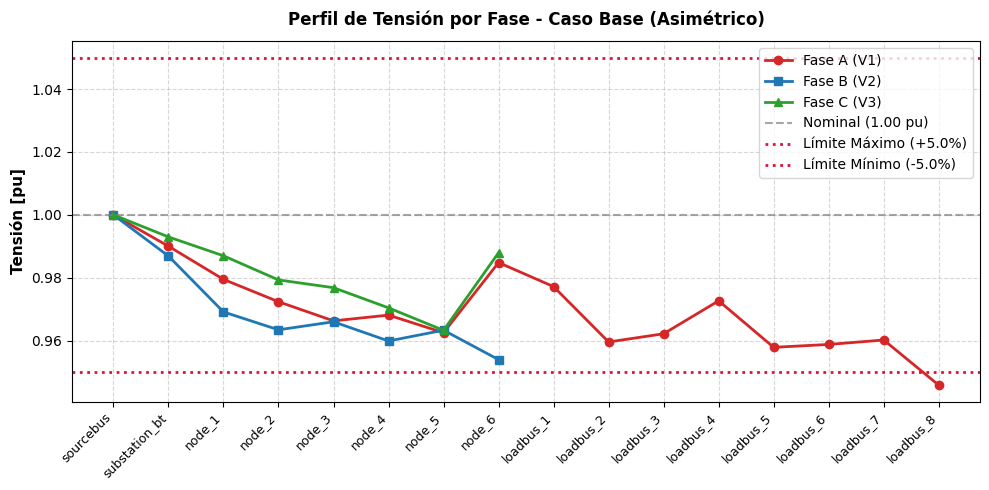

In [4]:
snapshot = get_network_snapshot(dss)
fig = plot_voltage_profile(snapshot["buses"], v_min=0.95, v_max=1.05, 
                           title="Perfil de Tensión por Fase - Caso Base (Asimétrico)")
plt.show()


---
### 5. Ejercicio Guiado: Rebalanceo de Cargas y Reducción de Pérdidas

**Problema:**
La Fase B está significativamente sobrecargada respecto a la Fase C:
* Demanda en Fase A: 22.0 kW
* Demanda en Fase B: 24.5 kW
* Demanda en Fase C: 15.5 kW

La acometida `Drop_L8` alimenta a `Load_8` (11.0 kW) conectada a la Fase B (`Node_6.2`).
Reconecte la acometida y la carga a la **Fase C** (`Node_6.3`), resuelva el flujo y compruebe:
1. Reducción de la corriente de neutro en cabecera.
2. Disminución de las pérdidas Joule en la red.
3. Mejora en la tensión mínima del sistema.


           EVALUACIÓN DEL REBALANCEO DE FASES
Métrica                     | Caso Base    | Rebalanceado | Variación
----------------------------|--------------|--------------|-----------
Corriente de Neutro |In|     |    36.36 A   |    59.63 A   |   +23.27 A
Pérdidas Totales (kW)       |    2.488 kW  |    2.586 kW  |   +0.098 kW
Tensión Mínima de Red       |   0.9459 pu  |   0.9396 pu  |  -0.0063 pu
[OK] Conexión de Fase restaurada al estado original del laboratorio.


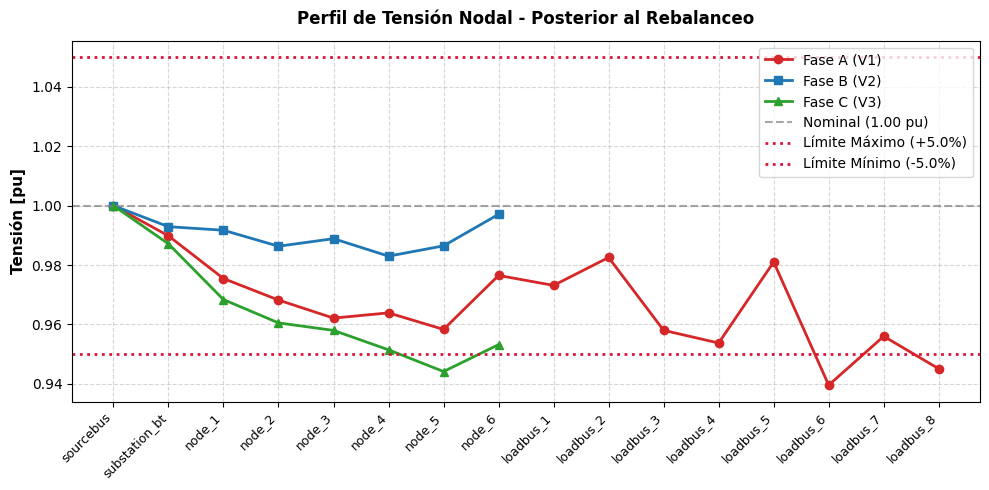

In [5]:
# 1. Guardar métricas del estado inicial
p_losses_inicial = dss.circuit.losses[0] / 1000.0
v_min_inicial = snapshot["buses"]["V_min_pu"].min()
i_neutro_inicial = i_neutro_mag

# 2. Reubicar Drop_L8 y Load_8 a Fase C (nodo 3)
dss.text("Edit Line.Drop_L8 bus1=Node_6.3 bus2=LoadBus_8.1")
dss.solution.solve()

# 3. Recalcular fasores en cabecera
dss.circuit.set_active_element("Line.line_sub_n1")
cma = dss.cktelement.currents_mag_ang
ia_re = cma[0] * np.exp(1j * np.radians(cma[1]))
ib_re = cma[2] * np.exp(1j * np.radians(cma[3]))
ic_re = cma[4] * np.exp(1j * np.radians(cma[5]))
i_neutro_balanceado = abs(-(ia_re + ib_re + ic_re))

# 4. Extraer nuevas métricas
snap_bal = get_network_snapshot(dss)
p_losses_balanceado = dss.circuit.losses[0] / 1000.0
v_min_balanceado = snap_bal["buses"]["V_min_pu"].min()

print("=================================================================")
print("           EVALUACIÓN DEL REBALANCEO DE FASES")
print("=================================================================")
print(f"Métrica                     | Caso Base    | Rebalanceado | Variación")
print(f"----------------------------|--------------|--------------|-----------")
print(f"Corriente de Neutro |In|     | {i_neutro_inicial:8.2f} A   | {i_neutro_balanceado:8.2f} A   | {(i_neutro_balanceado - i_neutro_inicial):+8.2f} A")
print(f"Pérdidas Totales (kW)       | {p_losses_inicial:8.3f} kW  | {p_losses_balanceado:8.3f} kW  | {(p_losses_balanceado - p_losses_inicial):+8.3f} kW")
print(f"Tensión Mínima de Red       | {v_min_inicial:8.4f} pu  | {v_min_balanceado:8.4f} pu  | {(v_min_balanceado - v_min_inicial):+8.4f} pu")
print("=================================================================")

fig_bal = plot_voltage_profile(snap_bal["buses"], v_min=0.95, v_max=1.05,
                               title="Perfil de Tensión Nodal - Posterior al Rebalanceo")
plt.show()

# Revertir a la condición base para coherencia con módulos posteriores
dss.text("Edit Line.Drop_L8 bus1=Node_6.2 bus2=LoadBus_8.1")
dss.solution.solve()
print("[OK] Conexión de Fase restaurada al estado original del laboratorio.")


---
### Conclusiones del Módulo 1
1. El modelado riguroso de conductores trifásicos y monofásicos mediante `LineCode` refleja con precisión el desbalance de impedancias y las secciones reducidas de neutro.
2. El desbalance de fase genera corrientes netas de retorno por el neutro que incrementan las pérdidas $I^2 R$ e inducen caídas de tensión heterogéneas.
3. La redistribución estratégica de acometidas monofásicas equilibra las corrientes de fase, disminuye el flujo por el neutro y mitiga la degradación de tensión sin requerir inversión en nuevo conductor.
